# Inflation forecasting: 2022–2025

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'modelling').is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from modelling.regime_experiment import notebook_result_table, plot_notebook_forecasts, plot_predicted_regimes

RESULTS_FILE = PROJECT_ROOT / 'data/processed/model_results/results_static_2022_2025.json'
RISK_RESULTS_FILE = PROJECT_ROOT / 'data/processed/model_results/results_subject_risk_2022_2025.json'
TEST_START, TEST_END = '2022-01-01', '2025-11-01'
if not RESULTS_FILE.exists():
    raise FileNotFoundError('Run `python -m modelling.regime_experiment` before opening Notebook 2.')
results = json.loads(RESULTS_FILE.read_text(encoding='utf-8'))
risk_results = json.loads(RISK_RESULTS_FILE.read_text(encoding='utf-8'))
expected_signature = {'test_start': TEST_START, 'test_end': TEST_END, 'version': 5, 'main_estimation': 'static'}
mismatches = {key: (results.get('signature', {}).get(key), value)
              for key, value in expected_signature.items()
              if results.get('signature', {}).get(key) != value}
if mismatches:
    raise ValueError(f'Results do not match Notebook 2 configuration: {mismatches}')
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.Series(results['sample'], name='Current comparison').to_frame())

,Current comparison
training_start,2008-07-01
initial_training_end,2021-12-01
scored_start,2022-01-01
scored_end,2025-09-01
scored_months,45
unavailable_months,"[2025-10, 2025-11]"
timing,Static coefficients estimated through December...
data_vintage,"Latest revised FRED data, not a real-time vint..."


In [2]:
def show_comparison(group):
    table = notebook_result_table(results, group)
    display(table.drop(columns='key').round(4))
    return table

def plot_rmse(table, title):
    ordered = table.sort_values('rmse', ascending=False)
    ax = ordered.plot.barh(x='model', y='rmse', legend=False, figsize=(12, max(3, .28 * len(ordered))))
    ax.set(xlabel='RMSE (percentage points)', ylabel='', title=title)
    ax.grid(axis='x', alpha=.2)
    plt.tight_layout()
    plt.show()

def matching_ar_gains(table):
    table = table.copy()
    ar = {tuple(results['models'][row.key]['features']): row.rmse
          for row in table.itertuples() if row.family == 'AR'}
    table['gain_vs_matching_AR_pct'] = [
        100 * (1 - row.rmse / ar[tuple(results['models'][row.key]['features'])])
        if row.family in ('AR-HMM', 'MS-Variance') else np.nan for row in table.itertuples()
    ]
    return table

## Static baselines

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast
0,Static AR-HMM + lagged sentiment,AR-HMM,static,0.2615,0.1815,0.0708
1,Static AR(1),AR,static,0.2637,0.1825,0.0674
2,Static ARX + sentiment,AR,static,0.2639,0.1830,0.0692
3,Static LASSO,LASSO,static,0.2671,0.1854,0.0836
4,Static LASSO + sentiment,LASSO,static,0.2679,0.1836,0.0994
5,Static HMM,HMM,static,0.3025,0.1972,0.1424
6,Static AR-HMM,AR-HMM,static,0.3035,0.1972,0.0539


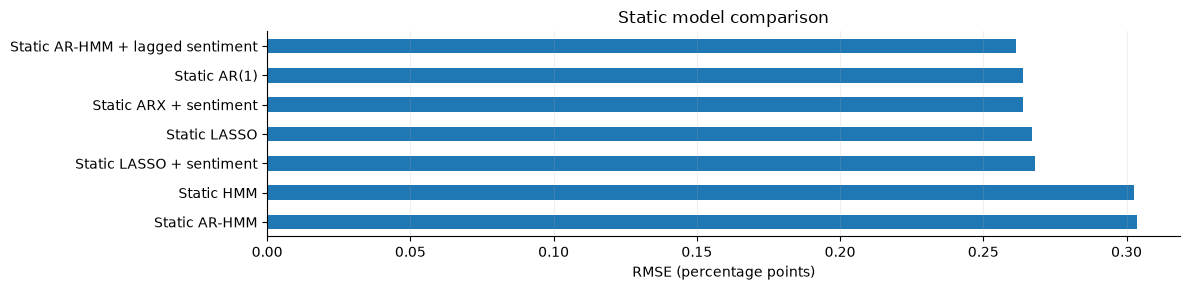

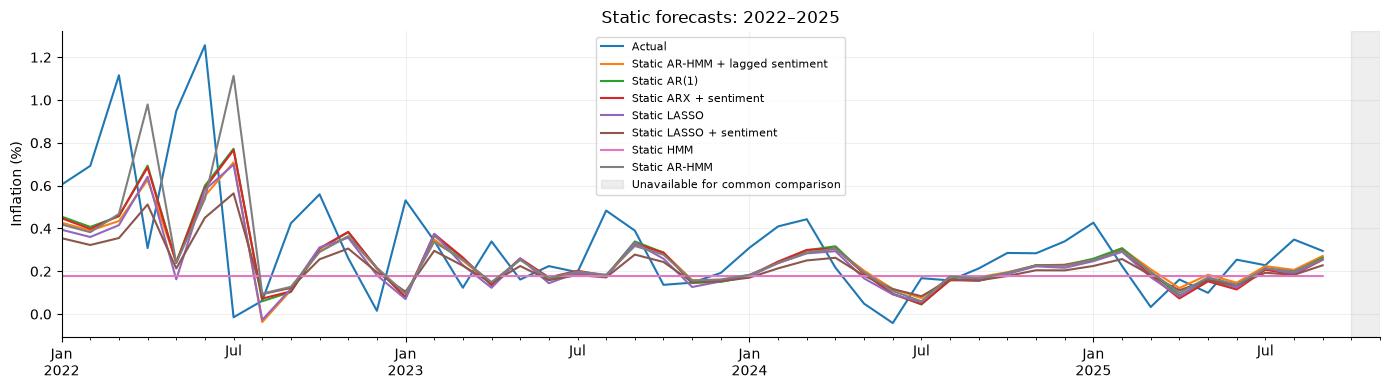

In [3]:
static_table = show_comparison('Static baselines')
plot_rmse(static_table, 'Static model comparison')
plot_notebook_forecasts(results, static_table['key'], 'Static forecasts: 2022–2025')
plt.show()

## Expanding-window effect

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast
0,Static AR(1),AR,static,0.2637,0.1825,0.0674
1,Expanding AR(1),AR,expanding,0.2655,0.1817,0.0546
2,Expanding AR-HMM(1) · 2 states,AR-HMM,expanding,0.2671,0.1855,0.0635
3,Static AR-HMM,AR-HMM,static,0.3035,0.1972,0.0539


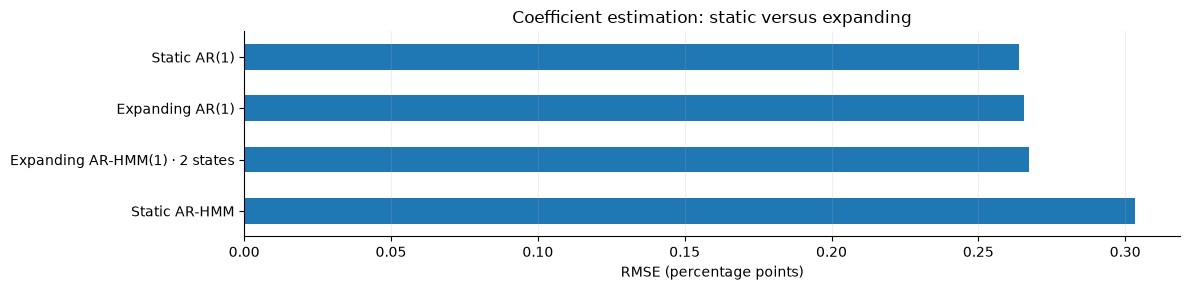

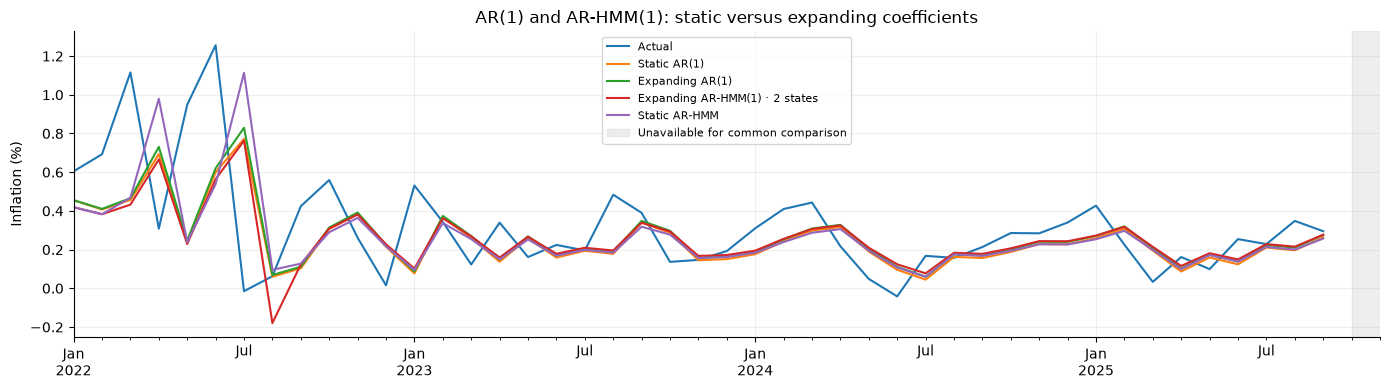

In [4]:
window_table = show_comparison('Static vs expanding')
plot_rmse(window_table, 'Coefficient estimation: static versus expanding')
plot_notebook_forecasts(results, window_table['key'], 'AR(1) and AR-HMM(1): static versus expanding coefficients')
plt.show()

## Static two-state AR-HMM: alternative switching structures
The number of states stays fixed at two. These specifications test whether regimes are better identified when the AR coefficient is common, when volatility switches, or when only volatility switches. Model coefficients are estimated once through December 2021; the charts use probabilities available before observing each test-month outcome. The preferred variance-only model labels its regimes Low volatility and High volatility because its conditional mean equation is common across states.

,model,rmse,bic_training,level_1_share,level_2_share,level_1_sd,level_2_sd,mean_classification_confidence
0,Switching variance only · common intercept and AR,0.2612,-6.3672,0.7778,0.2222,0.1457,0.4526,0.8258
1,Switching intercept · common AR · common variance,0.2617,12.8862,0.0000,1.0000,0.2188,0.2188,0.9927
2,Switching intercept + variance · common AR,0.2648,-1.6790,0.2000,0.8000,0.4574,0.1473,0.8300
3,Static AR-HMM,0.3035,13.2953,0.0000,1.0000,0.2044,0.2044,0.8901


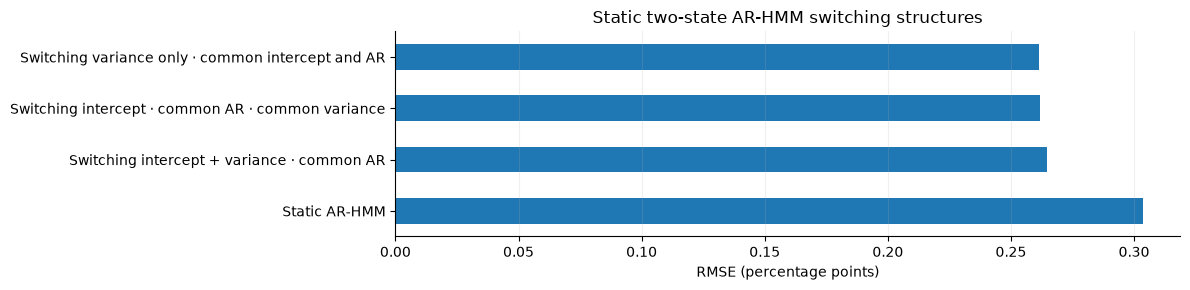

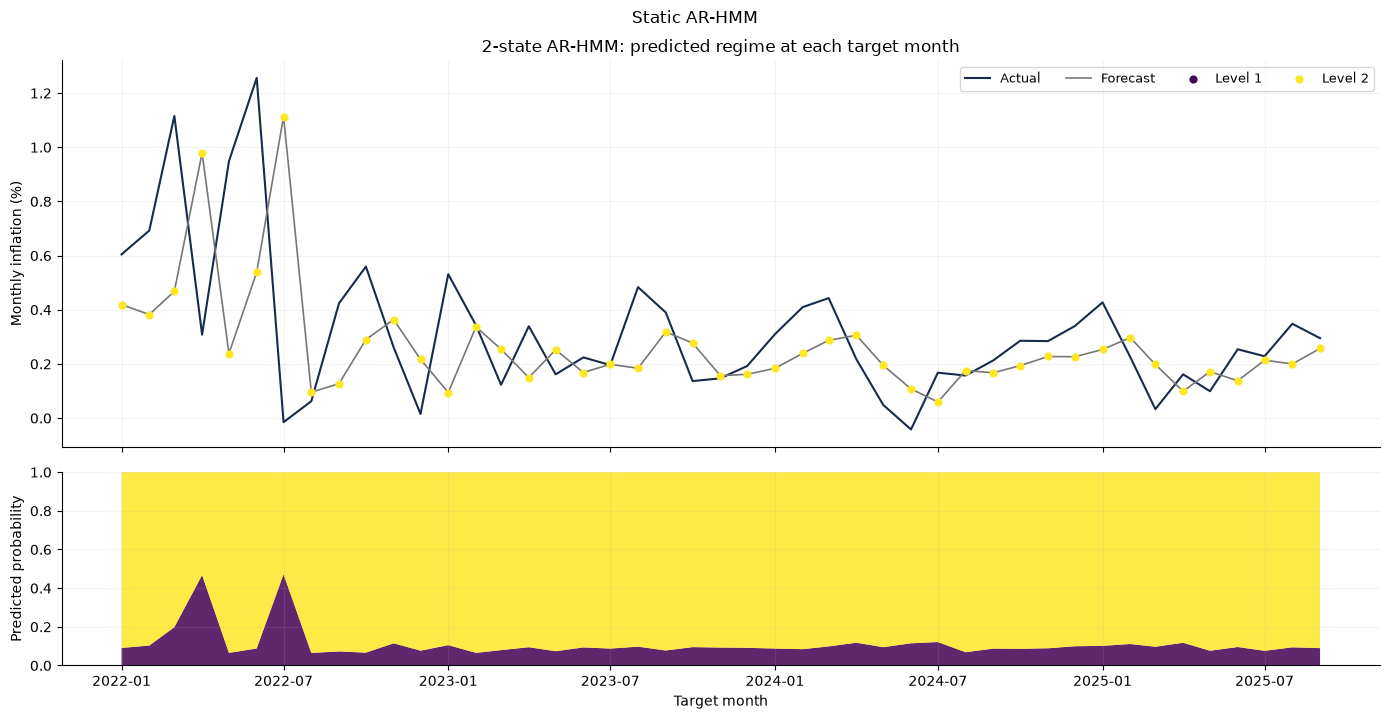

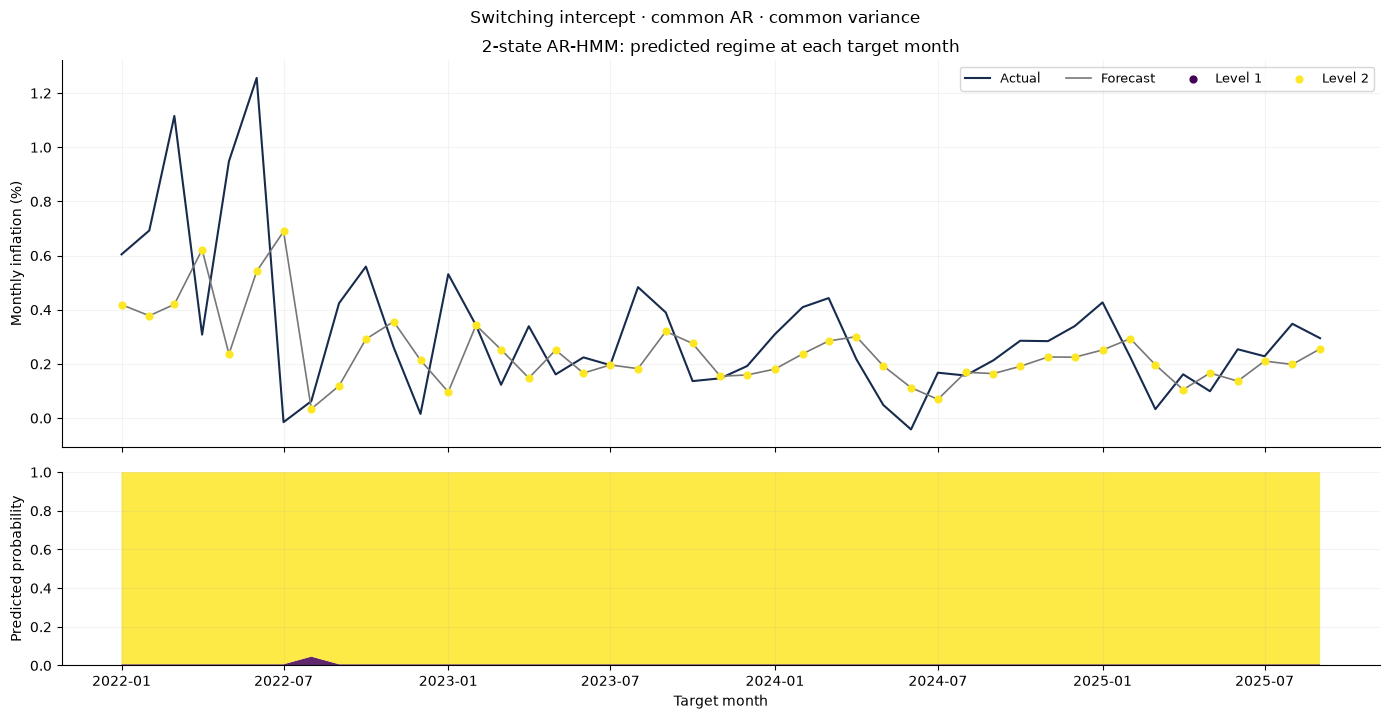

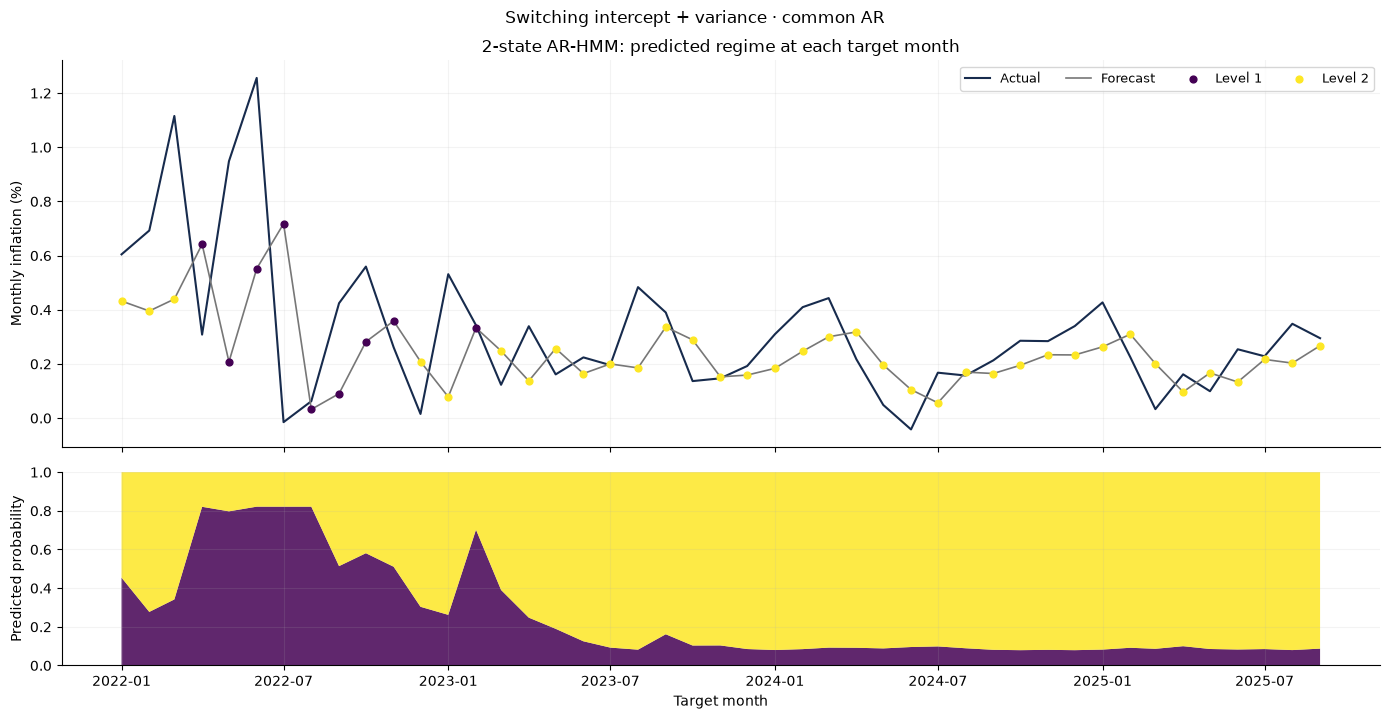

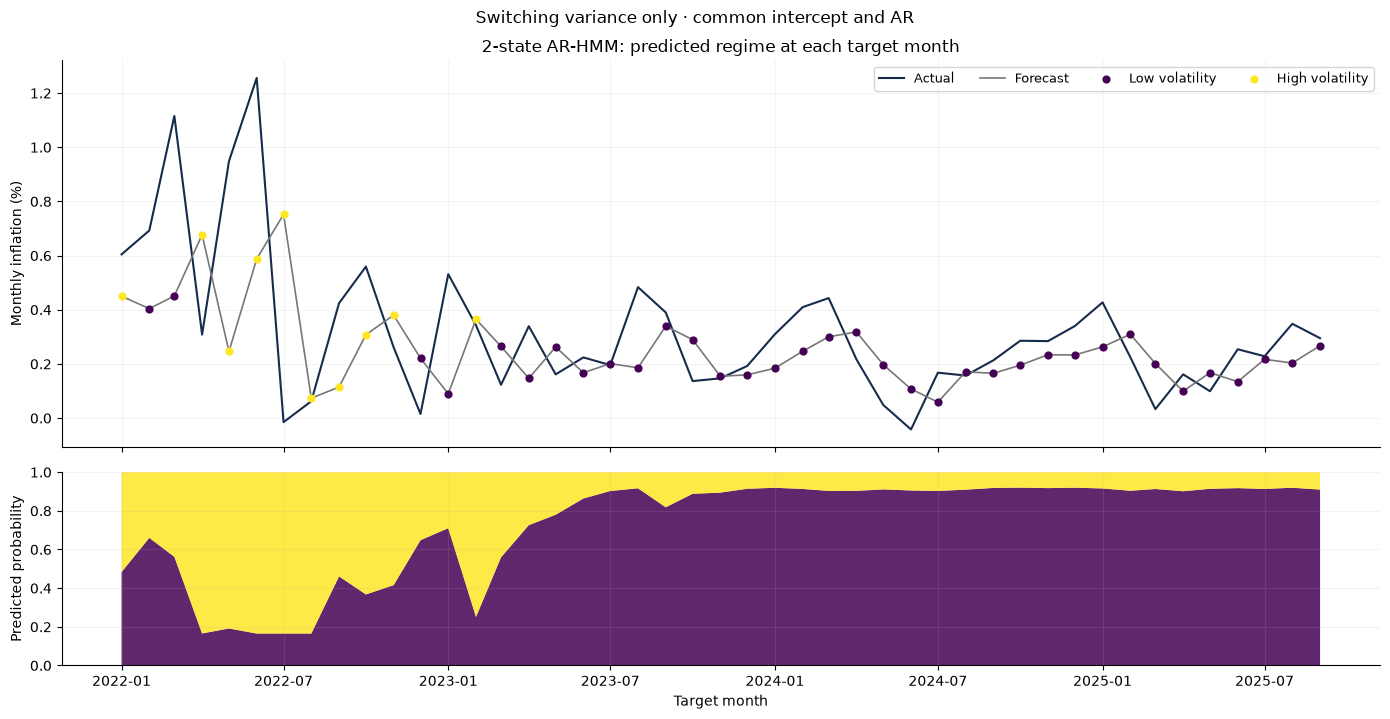

In [5]:
structure_table = notebook_result_table(results, 'MoM two-state structures')
structure_rows = []
for row in structure_table.itertuples():
    model = results['models'][row.key]
    frame = pd.DataFrame(model['forecasts'])
    labels = model['parameters']['regime_labels']
    order = model['parameters']['raw_state_order']
    variances = np.asarray(model['parameters']['state_variances'])[order]
    shares = frame.PredictedRegime.value_counts(normalize=True).reindex(labels, fill_value=0)
    probabilities = frame[[f'Probability_{label}' for label in labels]]
    structure_rows.append({
        'model': model['name'], 'rmse': row.rmse, 'bic_training': model['parameters']['bic'],
        'level_1_share': shares.iloc[0], 'level_2_share': shares.iloc[1],
        'level_1_sd': np.sqrt(variances[0]), 'level_2_sd': np.sqrt(variances[1]),
        'mean_classification_confidence': probabilities.max(axis=1).mean(),
    })
structure_summary = pd.DataFrame(structure_rows).sort_values('rmse').reset_index(drop=True)
display(structure_summary.round(4))
plot_rmse(structure_table, 'Static two-state AR-HMM switching structures')
for key in results['groups']['MoM two-state structures']:
    model = results['models'][key]
    frame = pd.DataFrame(model['forecasts'])
    frame['Date'] = pd.to_datetime(frame['Date'])
    labels = model['parameters']['regime_labels']
    plot_predicted_regimes(frame, labels)
    plt.suptitle(model['name'], y=1.02)
    plt.show()

## Preferred specification for the remaining analysis
The two-state variance-switching model with a common intercept and common coefficients has the best training BIC, the lowest test RMSE, and uses both regimes. It is therefore used below for every lag, macroeconomic and sentiment comparison. The model is labelled **MS-Variance AR**: its states describe normal versus turbulent inflation volatility, not low versus high conditional mean inflation.

## Monthly inflation: static lag orders 1–6

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,MoM MS-Variance AR(1) · 2 states,MS-Variance,static,0.2612,0.1803,0.0631,0.9512
1,Static AR(1),AR,static,0.2637,0.1825,0.0674,NaN
2,MoM MS-Variance AR(5) · 2 states,MS-Variance,static,0.2682,0.1834,0.0657,5.4422
3,MoM MS-Variance AR(4) · 2 states,MS-Variance,static,0.2701,0.1844,0.0712,2.4652
4,MoM MS-Variance AR(2) · 2 states,MS-Variance,static,0.2712,0.1865,0.0895,1.8823
5,MoM AR(3),AR,static,0.2763,0.1924,0.0854,NaN
6,MoM AR(2),AR,static,0.2764,0.1924,0.0854,NaN
7,MoM AR(4),AR,static,0.2770,0.1921,0.0798,NaN
8,MoM MS-Variance AR(3) · 2 states,MS-Variance,static,0.2775,0.1898,0.0957,-0.4133
9,MoM MS-Variance AR(6) · 2 states,MS-Variance,static,0.2808,0.1906,0.0943,1.3338


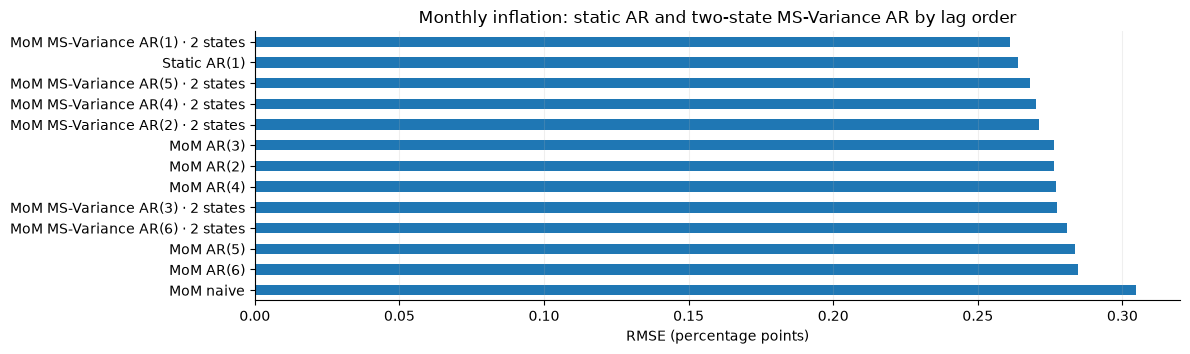

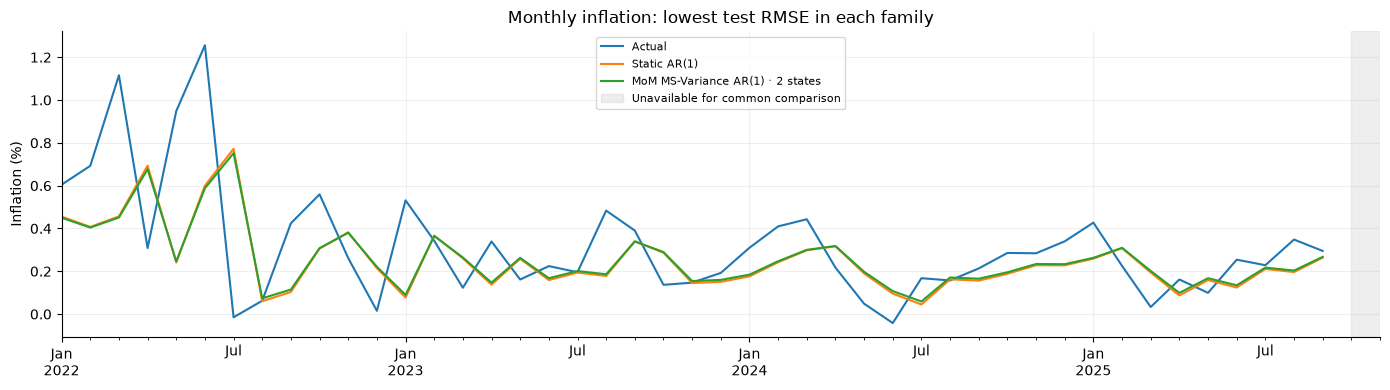

In [6]:
mom_lags = matching_ar_gains(notebook_result_table(results, 'MoM lag orders'))
display(mom_lags.drop(columns='key').round(4))
plot_rmse(mom_lags, 'Monthly inflation: static AR and two-state MS-Variance AR by lag order')
best_mom_keys = mom_lags.loc[mom_lags.family.isin(['AR', 'MS-Variance'])].sort_values('rmse').groupby('family').first()['key'].tolist()
plot_notebook_forecasts(results, best_mom_keys, 'Monthly inflation: lowest test RMSE in each family')
plt.show()

## MoM: static macroeconomic indicators with the preferred MS-Variance model

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,MoM MS-Variance AR(1) + Unemployment + Industry,MS-Variance,static,0.2612,0.1803,0.0637,1.0883
1,MoM MS-Variance AR(1) + Industry,MS-Variance,static,0.2612,0.1803,0.0630,0.9617
2,MoM MS-Variance AR(1) · 2 states,MS-Variance,static,0.2612,0.1803,0.0631,0.9512
3,MoM MS-Variance AR(1) + Unemployment,MS-Variance,static,0.2613,0.1803,0.0639,1.0077
4,MoM MS-Variance AR(1) + Unemployment + Industr...,MS-Variance,static,0.2615,0.1839,0.0561,12.3027
5,MoM MS-Variance AR(1) + Unemployment + Fed rate,MS-Variance,static,0.2615,0.1839,0.0567,12.0539
6,MoM MS-Variance AR(1) + Fed rate,MS-Variance,static,0.2616,0.1839,0.0565,8.8181
7,MoM MS-Variance AR(1) + Industry + Fed rate,MS-Variance,static,0.2616,0.1840,0.0555,11.6852
8,Static AR(1),AR,static,0.2637,0.1825,0.0674,NaN
9,MoM AR(1) + Industry,AR,static,0.2638,0.1824,0.0668,NaN


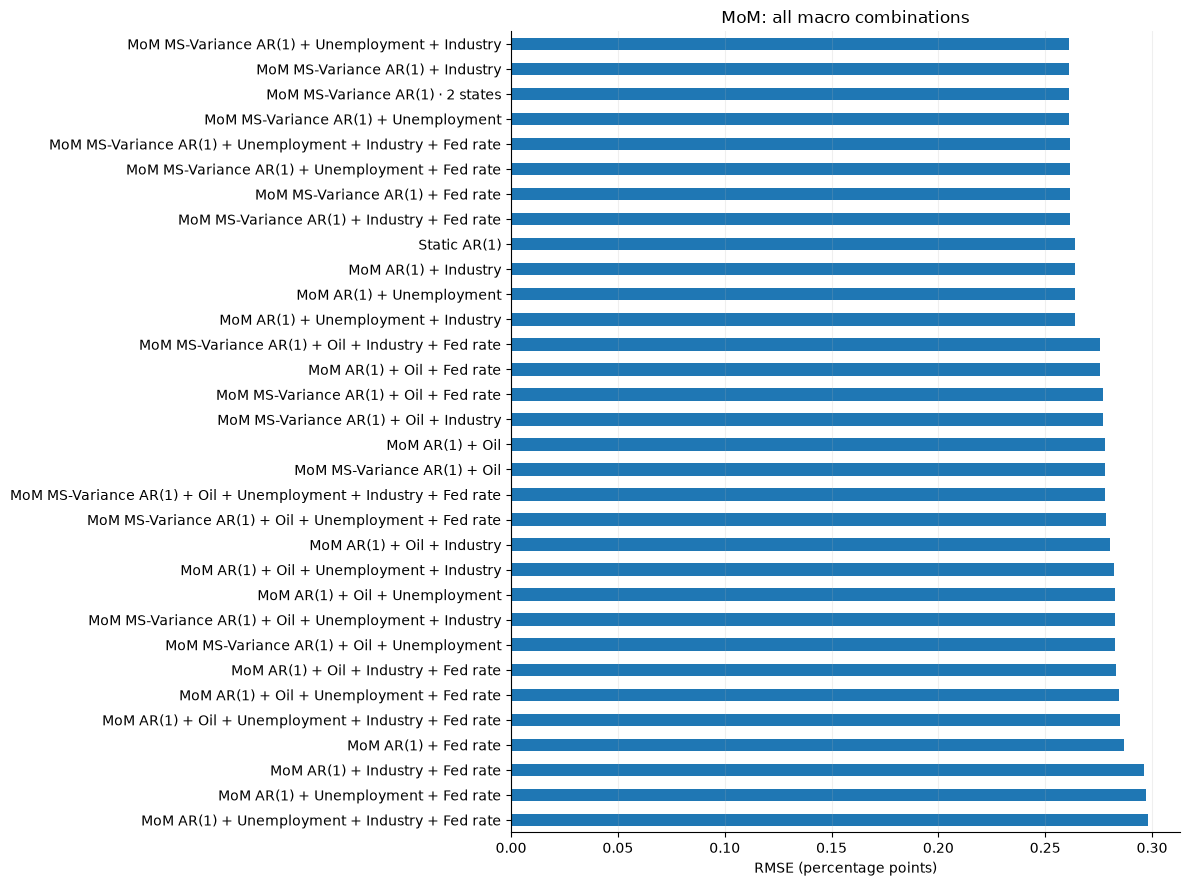

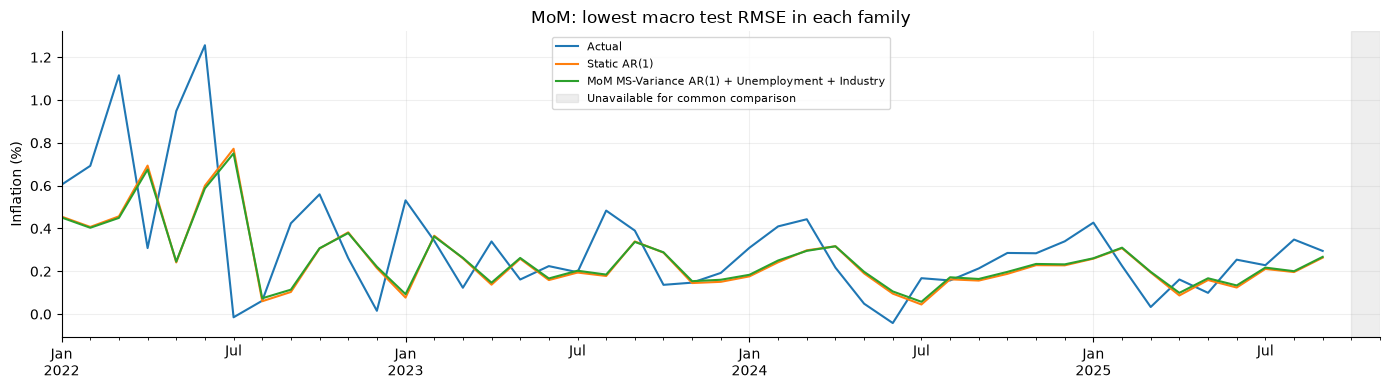

In [7]:
macro_table = matching_ar_gains(notebook_result_table(results, 'MoM macro'))
display(macro_table.drop(columns='key').round(4))
plot_rmse(macro_table, 'MoM: all macro combinations')
best_keys = macro_table.sort_values('rmse').groupby('family').first()['key'].tolist()
plot_notebook_forecasts(results, best_keys, 'MoM: lowest macro test RMSE in each family')
plt.show()

## MoM: static sentiment with and without macro inputs using MS-Variance

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast
0,MoM MS-Variance AR(1) + Unemployment + Industry,MS-Variance,static,0.2612,0.1803,0.0637
1,MoM MS-Variance AR(1) · 2 states,MS-Variance,static,0.2612,0.1803,0.0631
2,MoM MS-Variance AR(1) + Unemployment + Industr...,MS-Variance,static,0.2617,0.1814,0.0675
3,MoM MS-Variance AR(1) + sentiment,MS-Variance,static,0.2617,0.1814,0.0665
4,Static AR(1),AR,static,0.2637,0.1825,0.0674
5,MoM AR(1) + Industry,AR,static,0.2638,0.1824,0.0668
6,Static ARX + sentiment,AR,static,0.2639,0.1830,0.0692
7,MoM AR(1) + Industry + sentiment,AR,static,0.2640,0.1831,0.0685


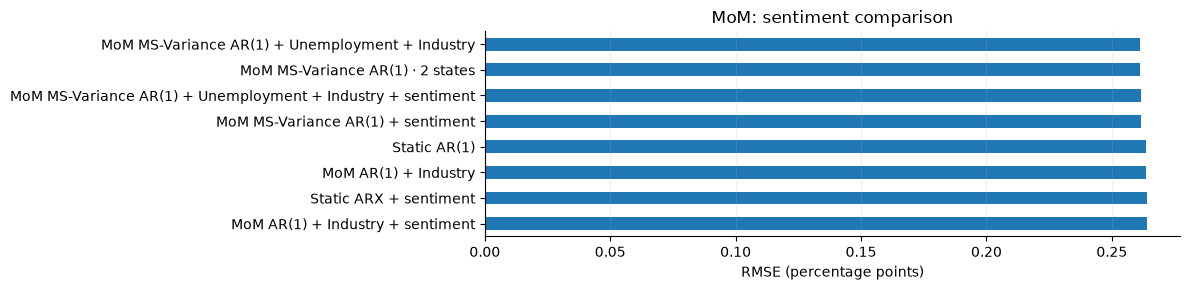

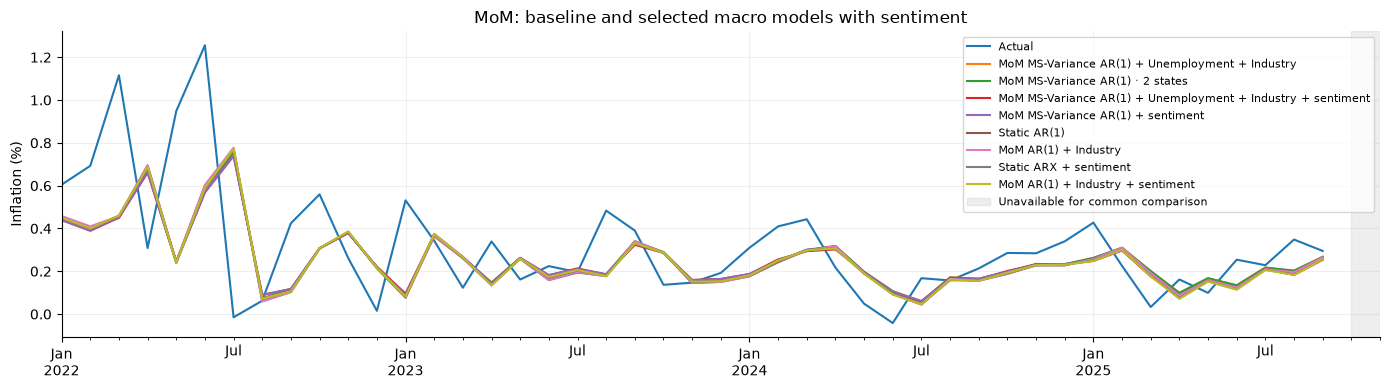

In [8]:
sentiment_table = show_comparison('MoM sentiment')
plot_rmse(sentiment_table, 'MoM: sentiment comparison')
plot_notebook_forecasts(results, sentiment_table['key'], 'MoM: baseline and selected macro models with sentiment')
plt.show()

## Monthly inflation: static alternative FinBERT aggregations using MS-Variance

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,MoM AR(1) + Sentiment_Std,AR,static,0.2610,0.1807,0.0594,NaN
1,MoM MS-Variance AR(1) · 2 states,MS-Variance,static,0.2612,0.1803,0.0631,0.9512
2,MoM MS-Variance AR(1) + sentiment,MS-Variance,static,0.2617,0.1814,0.0665,0.8473
3,MoM MS-Variance AR(1) + Sentiment_Std,MS-Variance,static,0.2622,0.1809,0.0669,-0.4675
4,MoM AR(1) + Sentiment_Median,AR,static,0.2630,0.1814,0.0631,NaN
5,MoM AR(1) + Negative_Share,AR,static,0.2633,0.1819,0.0650,NaN
6,MoM MS-Variance AR(1) + Negative_Share,MS-Variance,static,0.2636,0.1829,0.0752,-0.1038
7,Static AR(1),AR,static,0.2637,0.1825,0.0674,NaN
8,MoM MS-Variance AR(1) + Sentiment_Median,MS-Variance,static,0.2637,0.1838,0.0747,-0.2903
9,Static ARX + sentiment,AR,static,0.2639,0.1830,0.0692,NaN


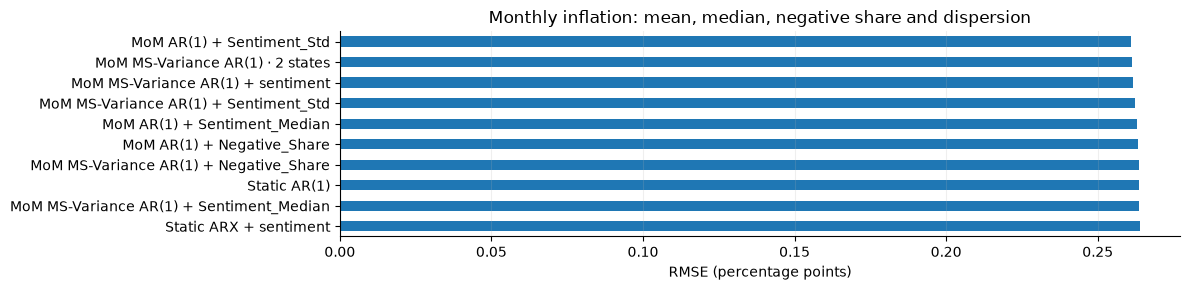

In [9]:
aggregation_table = matching_ar_gains(notebook_result_table(results, 'MoM sentiment aggregations'))
display(aggregation_table.drop(columns='key').round(4))
plot_rmse(aggregation_table, 'Monthly inflation: mean, median, negative share and dispersion')

## Monthly inflation: lagged subject-specific news risk

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast
0,MoM MS-Variance AR(1) · 2 states,MS-Variance,static,0.2612,0.1803,0.0631
1,Static AR-HMM,AR-HMM,static,0.2622,0.1813,0.0746
2,MoM MS-Variance AR(1) + Geopolitical_Risk,MS-Variance,static,0.2624,0.1811,0.0663
3,MoM AR(1) + Geopolitical_Risk,AR,static,0.2625,0.1814,0.0646
4,Static AR(1),AR,static,0.2637,0.1825,0.0674
5,MoM MS-Variance AR(1) + Supply_Chain_Risk,MS-Variance,static,0.2638,0.1816,0.0710
6,MoM AR-HMM(1) + Supply_Chain_Risk,AR-HMM,static,0.2643,0.1840,0.0786
7,MoM AR(1) + Supply_Chain_Risk,AR,static,0.2653,0.1835,0.0694
8,MoM MS-Variance AR(1) + Energy_Risk,MS-Variance,static,0.2692,0.1823,0.0814
9,MoM AR-HMM(1) + Geopolitical_Risk,AR-HMM,static,0.2713,0.1910,0.0914


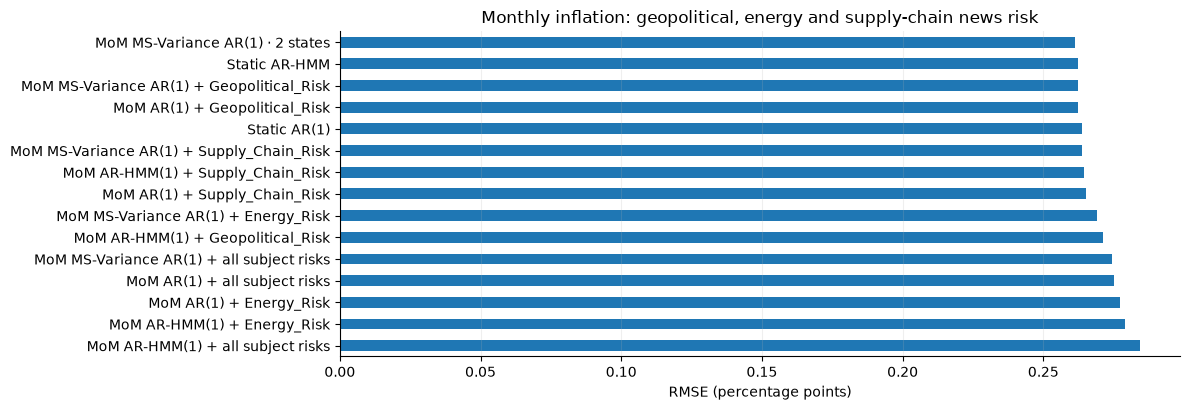

In [10]:
risk_table = notebook_result_table(risk_results, 'MoM subject risks')
display(risk_table.drop(columns='key').round(4))
plot_rmse(risk_table, 'Monthly inflation: geopolitical, energy and supply-chain news risk')

## Year-over-year inflation: static lag orders 1–6

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,YoY MS-Variance AR(3) · 2 states,MS-Variance,static,0.3684,0.3014,0.0213,11.4086
1,YoY MS-Variance AR(4) · 2 states,MS-Variance,static,0.3701,0.3031,0.0163,11.0914
2,YoY AR(1),AR,static,0.3781,0.2891,-0.0334,NaN
3,YoY MS-Variance AR(1) · 2 states,MS-Variance,static,0.3787,0.2897,-0.0409,-0.1803
4,YoY MS-Variance AR(2) · 2 states,MS-Variance,static,0.3795,0.3059,0.0930,11.5583
5,YoY MS-Variance AR(5) · 2 states,MS-Variance,static,0.3827,0.3092,0.0465,14.0479
6,YoY MS-Variance AR(6) · 2 states,MS-Variance,static,0.3835,0.3117,0.0614,14.6655
7,YoY naive,Naive,static,0.3911,0.2999,-0.0923,NaN
8,YoY AR(3),AR,static,0.4159,0.3255,0.1412,NaN
9,YoY AR(4),AR,static,0.4163,0.3270,0.1359,NaN


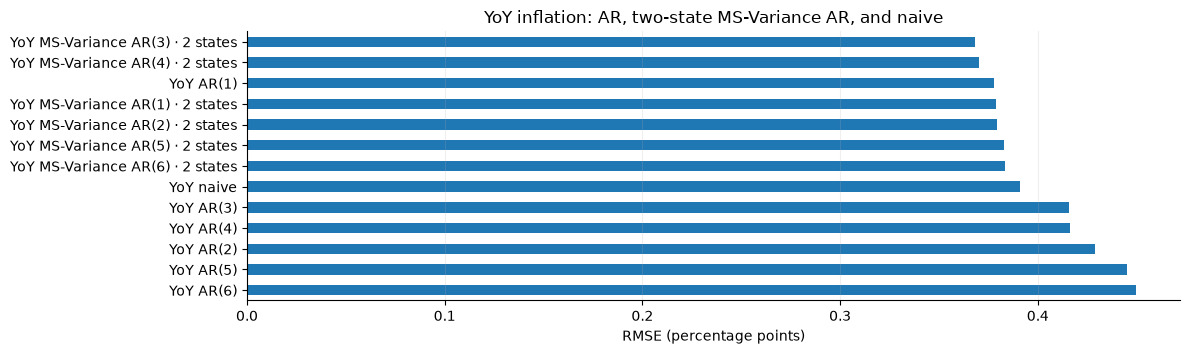

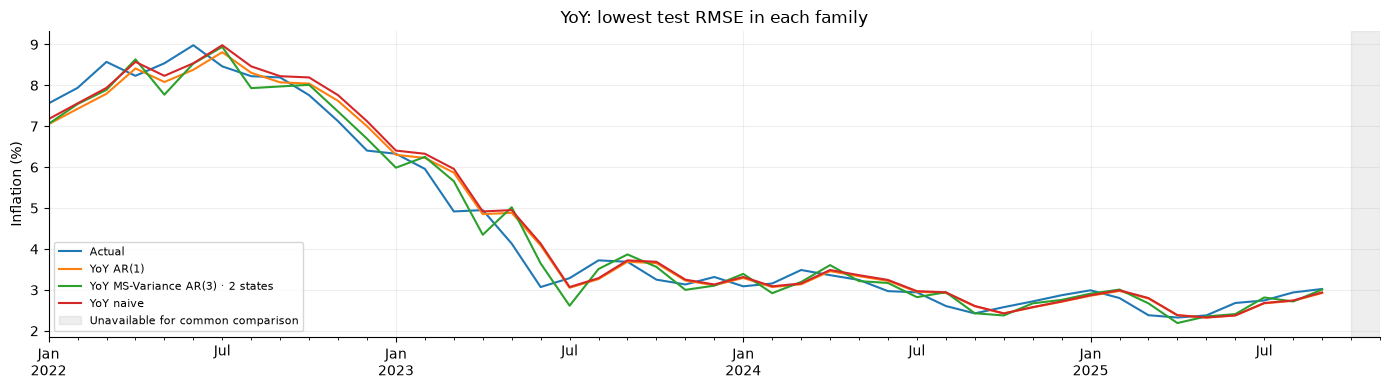

In [11]:
yoy_lags = matching_ar_gains(notebook_result_table(results, 'YoY lag orders'))
display(yoy_lags.drop(columns='key').round(4))
plot_rmse(yoy_lags, 'YoY inflation: AR, two-state MS-Variance AR, and naive')
best_yoy_keys = yoy_lags.loc[yoy_lags.family.isin(['AR', 'MS-Variance', 'Naive'])].sort_values('rmse').groupby('family').first()['key'].tolist()
plot_notebook_forecasts(results, best_yoy_keys, 'YoY: lowest test RMSE in each family')
plt.show()

## YoY: static macroeconomic indicators with the preferred MS-Variance model

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,YoY MS-Variance AR(2) + Industry,MS-Variance,static,0.3789,0.3054,0.0916,11.8878
1,YoY MS-Variance AR(2) · 2 states,MS-Variance,static,0.3795,0.3059,0.0930,11.5583
2,YoY MS-Variance AR(2) + Unemployment,MS-Variance,static,0.3837,0.3077,0.0992,10.8609
3,YoY MS-Variance AR(2) + Fed rate,MS-Variance,static,0.3861,0.3163,0.0910,5.3006
4,YoY MS-Variance AR(2) + Unemployment + Industry,MS-Variance,static,0.3862,0.3089,0.1032,10.2620
5,YoY AR(2) + Oil + Fed rate,AR,static,0.4028,0.3358,0.0994,NaN
6,YoY AR(2) + Oil + Industry + Fed rate,AR,static,0.4059,0.3407,0.0783,NaN
7,YoY AR(2) + Fed rate,AR,static,0.4077,0.3375,0.0939,NaN
8,YoY MS-Variance AR(2) + Oil + Industry + Fed rate,MS-Variance,static,0.4077,0.3368,0.1224,-0.4418
9,YoY AR(2) + Oil + Unemployment + Industry + Fe...,AR,static,0.4094,0.3449,0.0638,NaN


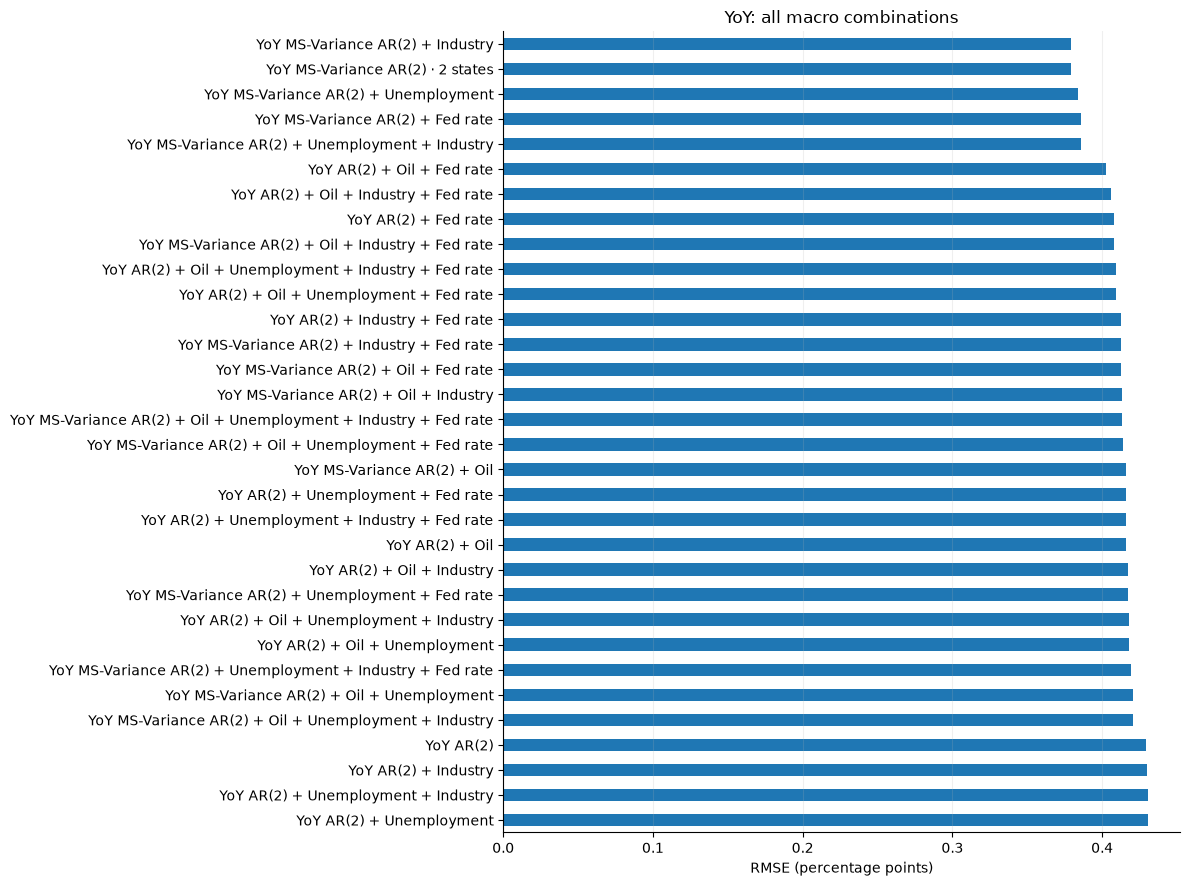

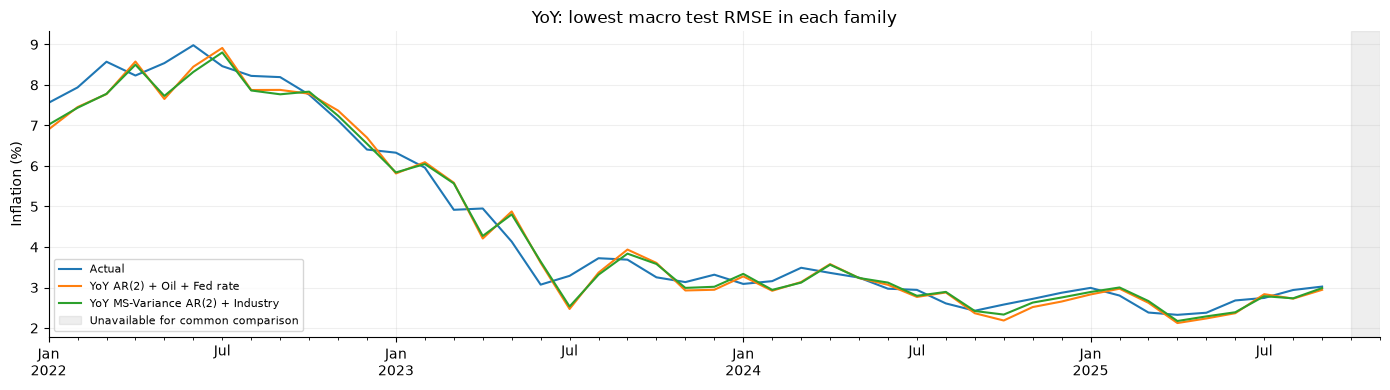

In [12]:
macro_table = matching_ar_gains(notebook_result_table(results, 'YoY macro'))
display(macro_table.drop(columns='key').round(4))
plot_rmse(macro_table, 'YoY: all macro combinations')
best_keys = macro_table.sort_values('rmse').groupby('family').first()['key'].tolist()
plot_notebook_forecasts(results, best_keys, 'YoY: lowest macro test RMSE in each family')
plt.show()

## YoY: static sentiment with and without macro inputs using MS-Variance

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast
0,YoY MS-Variance AR(2) + Industry,MS-Variance,static,0.3789,0.3054,0.0916
1,YoY MS-Variance AR(2) · 2 states,MS-Variance,static,0.3795,0.3059,0.0930
2,YoY MS-Variance AR(2) + Industry + sentiment,MS-Variance,static,0.3813,0.3063,0.0993
3,YoY MS-Variance AR(2) + sentiment,MS-Variance,static,0.3827,0.3071,0.1024
4,YoY AR(2) + Oil + Fed rate,AR,static,0.4028,0.3358,0.0994
5,YoY AR(2) + Oil + Fed rate + sentiment,AR,static,0.4033,0.3356,0.1046
6,YoY AR(2) + sentiment,AR,static,0.4282,0.3342,0.1802
7,YoY AR(2),AR,static,0.4291,0.3363,0.1769


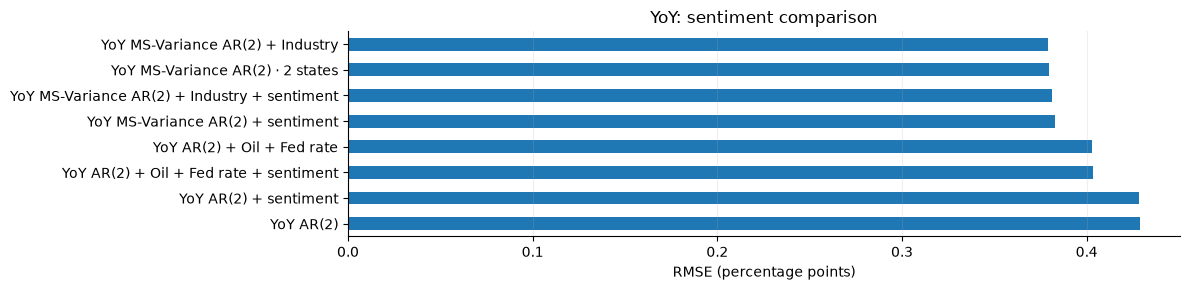

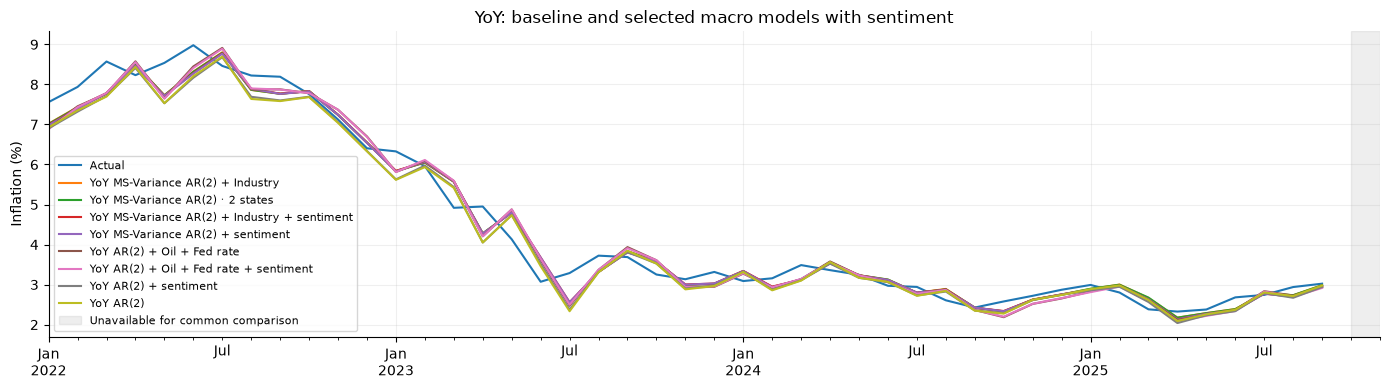

In [13]:
sentiment_table = show_comparison('YoY sentiment')
plot_rmse(sentiment_table, 'YoY: sentiment comparison')
plot_notebook_forecasts(results, sentiment_table['key'], 'YoY: baseline and selected macro models with sentiment')
plt.show()

## Overall static results

In [14]:
main_groups = ['Static baselines', 'MoM lag orders', 'MoM macro', 'MoM sentiment',
               'MoM sentiment aggregations', 'YoY lag orders', 'YoY macro', 'YoY sentiment']
main_keys = {key for group in main_groups for key in results['groups'][group]}
for target in ['Inflation_MoM', 'Inflation_YoY']:
    display(Markdown(f'**{target}**'))
    overall = pd.DataFrame([{'model': results['models'][key]['name'],
                             'family': results['models'][key]['family'],
                             'estimation': results['models'][key]['mode'],
                             **results['models'][key]['metrics']}
                            for key in main_keys if results['models'][key]['target'] == target
                            and results['models'][key]['mode'] == 'static']).sort_values('rmse')
    display(overall.round(4))

**Inflation_MoM**

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast
9,MoM AR(1) + Sentiment_Std,AR,static,0.2610,0.1807,0.0594
22,MoM MS-Variance AR(1) + Unemployment + Industry,MS-Variance,static,0.2612,0.1803,0.0637
24,MoM MS-Variance AR(1) + Industry,MS-Variance,static,0.2612,0.1803,0.0630
3,MoM MS-Variance AR(1) · 2 states,MS-Variance,static,0.2612,0.1803,0.0631
17,MoM MS-Variance AR(1) + Unemployment,MS-Variance,static,0.2613,0.1803,0.0639
35,Static AR-HMM + lagged sentiment,AR-HMM,static,0.2615,0.1815,0.0708
50,MoM MS-Variance AR(1) + Unemployment + Industr...,MS-Variance,static,0.2615,0.1839,0.0561
26,MoM MS-Variance AR(1) + Unemployment + Fed rate,MS-Variance,static,0.2615,0.1839,0.0567
8,MoM MS-Variance AR(1) + Fed rate,MS-Variance,static,0.2616,0.1839,0.0565
23,MoM MS-Variance AR(1) + Industry + Fed rate,MS-Variance,static,0.2616,0.1840,0.0555


**Inflation_YoY**

,model,family,estimation,rmse,mae,mean_error_actual_minus_forecast
29,YoY MS-Variance AR(3) · 2 states,MS-Variance,static,0.3684,0.3014,0.0213
35,YoY MS-Variance AR(4) · 2 states,MS-Variance,static,0.3701,0.3031,0.0163
33,YoY AR(1),AR,static,0.3781,0.2891,-0.0334
6,YoY MS-Variance AR(1) · 2 states,MS-Variance,static,0.3787,0.2897,-0.0409
36,YoY MS-Variance AR(2) + Industry,MS-Variance,static,0.3789,0.3054,0.0916
3,YoY MS-Variance AR(2) · 2 states,MS-Variance,static,0.3795,0.3059,0.0930
40,YoY MS-Variance AR(2) + Industry + sentiment,MS-Variance,static,0.3813,0.3063,0.0993
43,YoY MS-Variance AR(2) + sentiment,MS-Variance,static,0.3827,0.3071,0.1024
10,YoY MS-Variance AR(5) · 2 states,MS-Variance,static,0.3827,0.3092,0.0465
28,YoY MS-Variance AR(6) · 2 states,MS-Variance,static,0.3835,0.3117,0.0614
